In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "customer_booking.csv",
    encoding="latin1"
)

print(df.head())

   num_passengers sales_channel  trip_type  purchase_lead  length_of_stay  \
0               2      Internet  RoundTrip            262              19   
1               1      Internet  RoundTrip            112              20   
2               2      Internet  RoundTrip            243              22   
3               1      Internet  RoundTrip             96              31   
4               2      Internet  RoundTrip             68              22   

   flight_hour flight_day   route booking_origin  wants_extra_baggage  \
0            7        Sat  AKLDEL    New Zealand                    1   
1            3        Sat  AKLDEL    New Zealand                    0   
2           17        Wed  AKLDEL          India                    1   
3            4        Sat  AKLDEL    New Zealand                    0   
4           15        Wed  AKLDEL          India                    1   

   wants_preferred_seat  wants_in_flight_meals  flight_duration  \
0                     0        

In [3]:
# Number of rows and columns
print(df.shape)

# Column names
print(df.columns)

# Data types and non-null counts
df.info()

# Statistical summary
print(df.describe())

(50000, 14)
Index(['num_passengers', 'sales_channel', 'trip_type', 'purchase_lead',
       'length_of_stay', 'flight_hour', 'flight_day', 'route',
       'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat',
       'wants_in_flight_meals', 'flight_duration', 'booking_complete'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   w

In [4]:
# Missing values
print(df.isnull().sum())

# Duplicate records
print("Duplicates:", df.duplicated().sum())

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64
Duplicates: 719


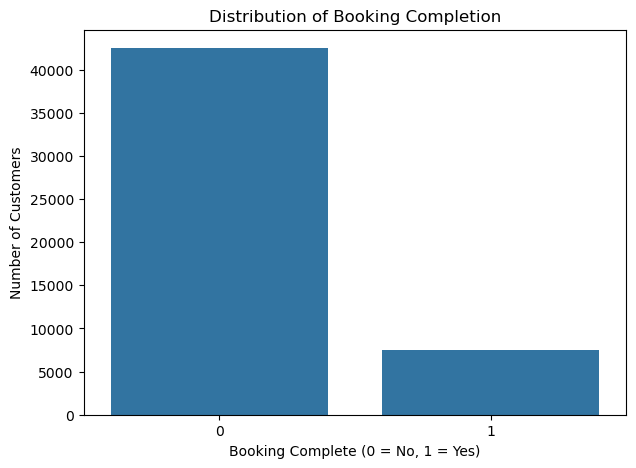

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="booking_complete"
)

plt.title("Distribution of Booking Completion")
plt.xlabel("Booking Complete (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

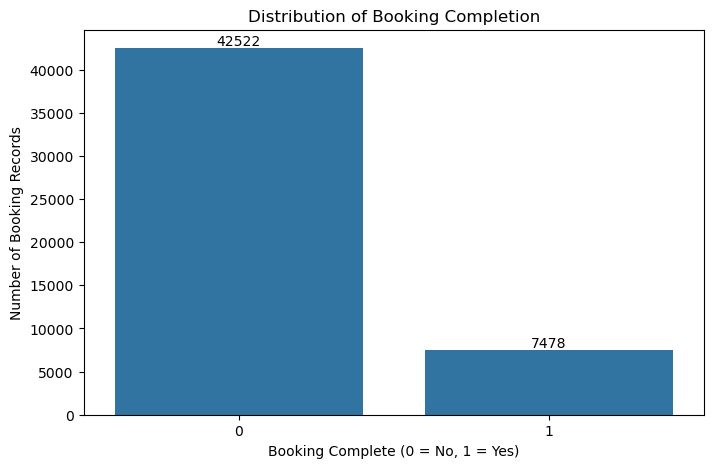

In [6]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="booking_complete"
)

total = len(df)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Booking Completion")
plt.xlabel("Booking Complete (0 = No, 1 = Yes)")
plt.ylabel("Number of Booking Records")

plt.show()

In [7]:
channel_analysis = df.groupby(
    "sales_channel"
)["booking_complete"].mean() * 100

print(channel_analysis)

sales_channel
Internet    15.476995
Mobile      10.840157
Name: booking_complete, dtype: float64


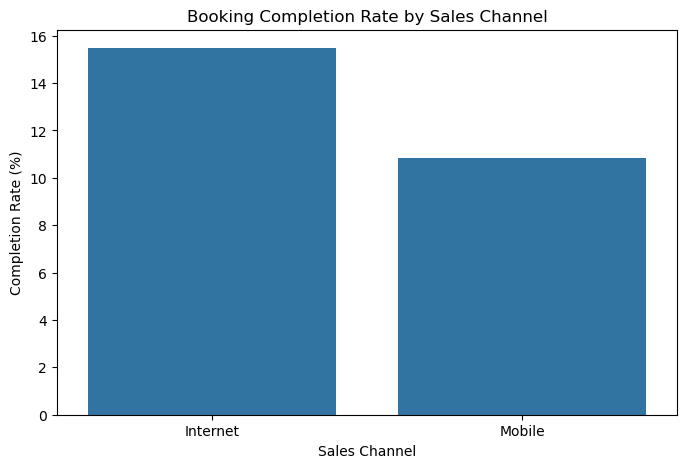

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=channel_analysis.index,
    y=channel_analysis.values
)

plt.title("Booking Completion Rate by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Completion Rate (%)")

plt.show()

In [9]:
trip_analysis = df.groupby(
    "trip_type"
)["booking_complete"].mean() * 100

print(trip_analysis)

trip_type
CircleTrip     4.310345
OneWay         5.167959
RoundTrip     15.057478
Name: booking_complete, dtype: float64


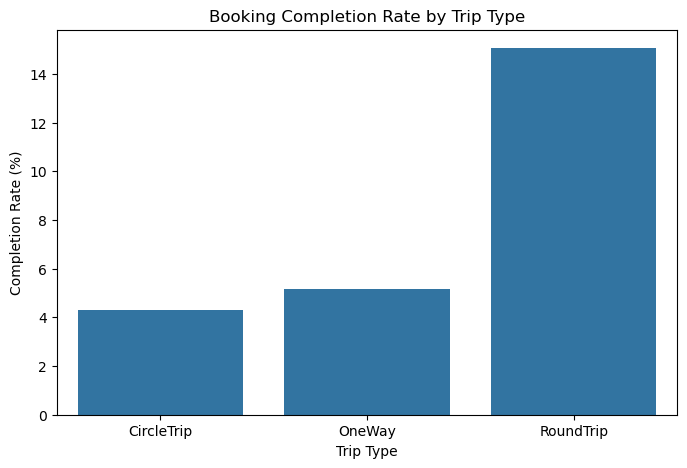

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=trip_analysis.index,
    y=trip_analysis.values
)

plt.title("Booking Completion Rate by Trip Type")
plt.xlabel("Trip Type")
plt.ylabel("Completion Rate (%)")

plt.show()

In [11]:
day_analysis = df.groupby(
    "flight_day"
)["booking_complete"].mean() * 100

print(day_analysis)

flight_day
Fri    14.539269
Mon    14.860528
Sat    14.814178
Sun    14.144034
Thu    15.113147
Tue    14.713932
Wed    16.314829
Name: booking_complete, dtype: float64


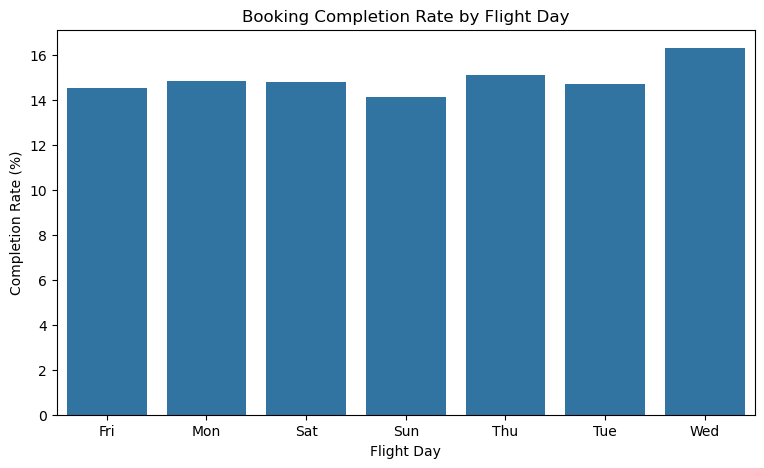

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis.values
)

plt.title("Booking Completion Rate by Flight Day")
plt.xlabel("Flight Day")
plt.ylabel("Completion Rate (%)")

plt.show()

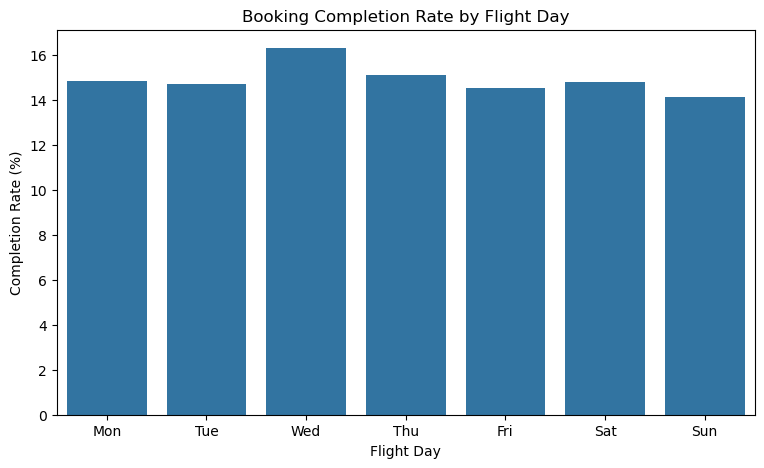

In [13]:
day_order = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

day_analysis = (
    df.groupby("flight_day")["booking_complete"]
    .mean() * 100
)

day_analysis = day_analysis.reindex(day_order)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=day_analysis.index,
    y=day_analysis.values
)

plt.title("Booking Completion Rate by Flight Day")
plt.xlabel("Flight Day")
plt.ylabel("Completion Rate (%)")

plt.show()

In [14]:
def analyse_category(column):

    result = df.groupby(column)["booking_complete"].agg(
        total_customers="count",
        completed_bookings="sum",
        completion_rate="mean"
    )

    result["completion_rate"] *= 100

    return result.sort_values(
        "completion_rate",
        ascending=False
    )


print(analyse_category("sales_channel"))

print(analyse_category("trip_type"))

print(analyse_category("flight_day"))

               total_customers  completed_bookings  completion_rate
sales_channel                                                      
Internet                 44382                6869        15.476995
Mobile                    5618                 609        10.840157
            total_customers  completed_bookings  completion_rate
trip_type                                                       
RoundTrip             49497                7453        15.057478
OneWay                  387                  20         5.167959
CircleTrip              116                   5         4.310345
            total_customers  completed_bookings  completion_rate
flight_day                                                      
Wed                    7674                1252        16.314829
Thu                    7424                1122        15.113147
Mon                    8102                1204        14.860528
Sat                    5812                 861        14.814178
Tue          

In [15]:
numerical_columns = [
    "num_passengers",
    "purchase_lead",
    "length_of_stay",
    "flight_hour",
    "flight_duration"
]

print(df[numerical_columns].describe().T)

                   count       mean        std   min    25%    50%     75%  \
num_passengers   50000.0   1.591240   1.020165  1.00   1.00   1.00    2.00   
purchase_lead    50000.0  84.940480  90.451378  0.00  21.00  51.00  115.00   
length_of_stay   50000.0  23.044560  33.887670  0.00   5.00  17.00   28.00   
flight_hour      50000.0   9.066340   5.412660  0.00   5.00   9.00   13.00   
flight_duration  50000.0   7.277561   1.496863  4.67   5.62   7.57    8.83   

                   max  
num_passengers     9.0  
purchase_lead    867.0  
length_of_stay   778.0  
flight_hour       23.0  
flight_duration    9.5  


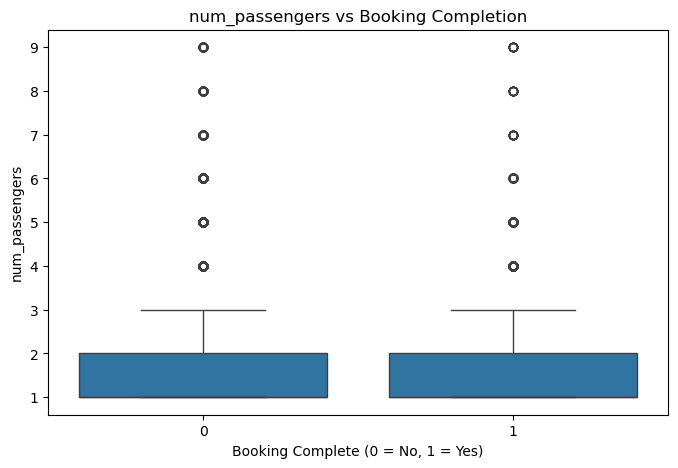

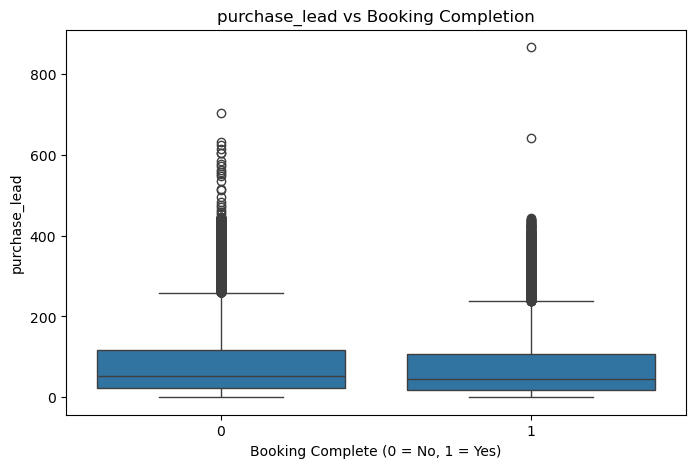

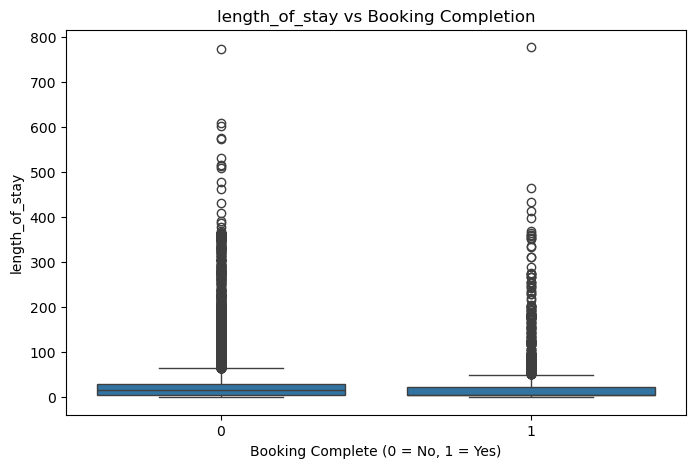

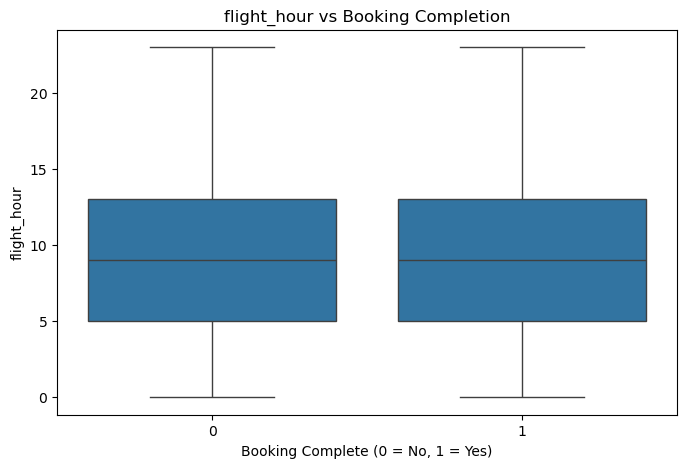

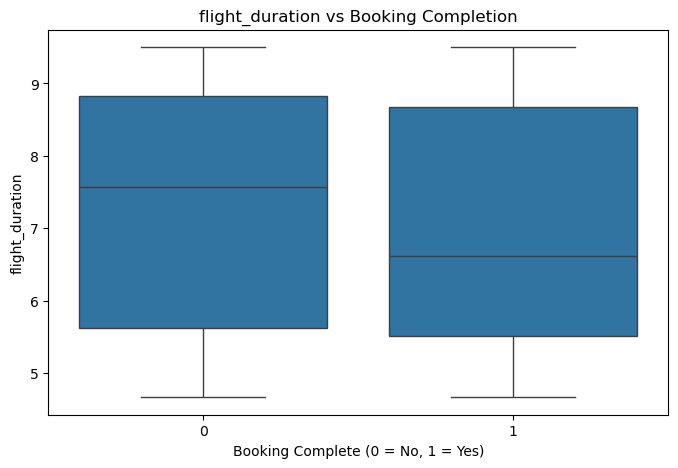

In [16]:
for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="booking_complete",
        y=column
    )

    plt.title(f"{column} vs Booking Completion")
    plt.xlabel("Booking Complete (0 = No, 1 = Yes)")
    plt.ylabel(column)

    plt.show()

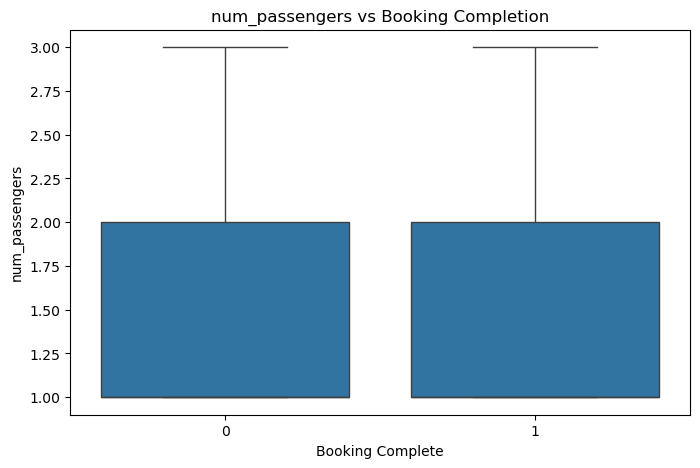

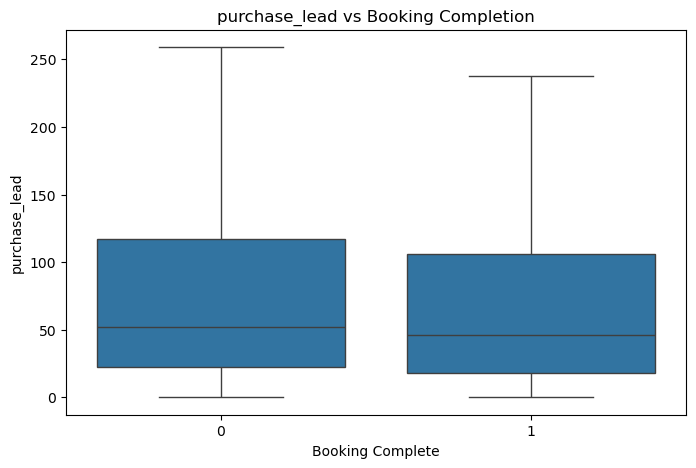

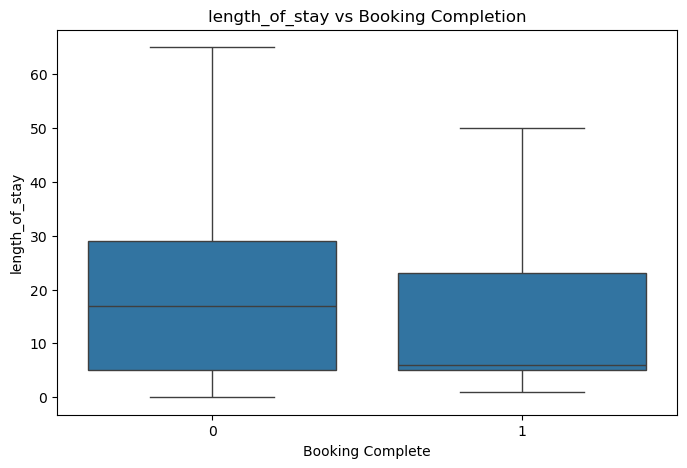

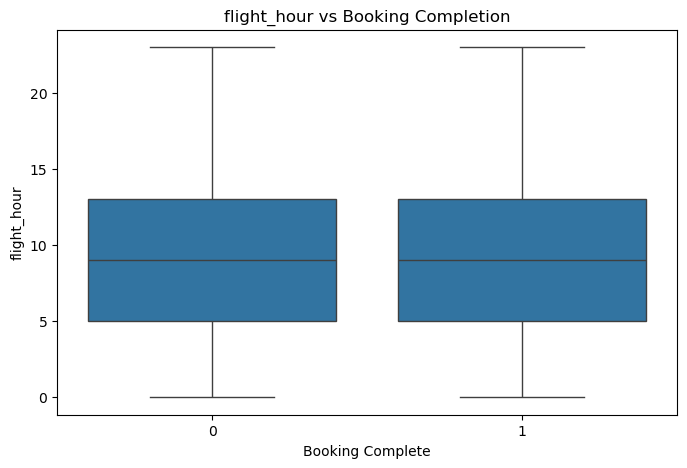

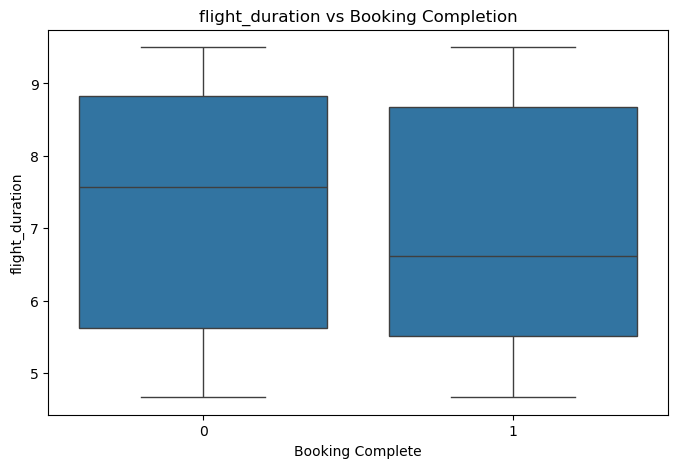

In [17]:
for column in numerical_columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="booking_complete",
        y=column,
        showfliers=False
    )

    plt.title(f"{column} vs Booking Completion")
    plt.xlabel("Booking Complete")
    plt.ylabel(column)

    plt.show()

In [18]:
categorical_columns = [
    "sales_channel",
    "trip_type",
    "flight_day",
    "route",
    "booking_origin"
]

for column in categorical_columns:

    print("\nColumn:", column)

    print("Unique values:", df[column].nunique())

    print(df[column].value_counts().head(10))


Column: sales_channel
Unique values: 2
sales_channel
Internet    44382
Mobile       5618
Name: count, dtype: int64

Column: trip_type
Unique values: 3
trip_type
RoundTrip     49497
OneWay          387
CircleTrip      116
Name: count, dtype: int64

Column: flight_day
Unique values: 7
flight_day
Mon    8102
Wed    7674
Tue    7673
Thu    7424
Fri    6761
Sun    6554
Sat    5812
Name: count, dtype: int64

Column: route
Unique values: 799
route
AKLKUL    2680
PENTPE     924
MELSGN     842
ICNSIN     801
DMKKIX     744
ICNSYD     695
DMKPER     679
DPSICN     666
DMKOOL     655
MELPEN     649
Name: count, dtype: int64

Column: booking_origin
Unique values: 104
booking_origin
Australia      17872
Malaysia        7174
South Korea     4559
Japan           3885
China           3387
Indonesia       2369
Taiwan          2077
Thailand        2030
India           1270
New Zealand     1074
Name: count, dtype: int64


In [19]:
origin_analysis = df.groupby(
    "booking_origin"
)["booking_complete"].agg(
    total_customers="count",
    completed_bookings="sum",
    completion_rate="mean"
)

origin_analysis["completion_rate"] *= 100

print(
    origin_analysis.sort_values(
        "total_customers",
        ascending=False
    ).head(15)
)

                total_customers  completed_bookings  completion_rate
booking_origin                                                      
Australia                 17872                 900         5.035810
Malaysia                   7174                2468        34.402007
South Korea                4559                 462        10.133801
Japan                      3885                 478        12.303732
China                      3387                 694        20.490109
Indonesia                  2369                 615        25.960321
Taiwan                     2077                 224        10.784786
Thailand                   2030                 470        23.152709
India                      1270                 131        10.314961
New Zealand                1074                  54         5.027933
Singapore                  1044                 299        28.639847
United States               456                  84        18.421053
Vietnam                     388   

In [20]:
route_counts = df["route"].value_counts()

print("Total unique routes:", df["route"].nunique())

print("\nTop 15 routes:")
print(route_counts.head(15))

Total unique routes: 799

Top 15 routes:
route
AKLKUL    2680
PENTPE     924
MELSGN     842
ICNSIN     801
DMKKIX     744
ICNSYD     695
DMKPER     679
DPSICN     666
DMKOOL     655
MELPEN     649
MELTPE     644
SGNSYD     614
DMKSYD     532
COKSYD     511
COKMEL     474
Name: count, dtype: int64


In [21]:
def category_analysis(column, min_count=100):

    result = df.groupby(column)["booking_complete"].agg(
        total_customers="count",
        completed_bookings="sum",
        completion_rate="mean"
    )

    result["completion_rate"] *= 100

    # Only retain categories with at least 100 records
    result = result[
        result["total_customers"] >= min_count
    ]

    return result.sort_values(
        "completion_rate",
        ascending=False
    )


# Booking origin analysis
origin_results = category_analysis("booking_origin")

print("Top booking origins by completion rate:")
print(origin_results.head(10))

# Route analysis
route_results = category_analysis("route")

print("\nTop routes by completion rate:")
print(route_results.head(10))

Top booking origins by completion rate:
                total_customers  completed_bookings  completion_rate
booking_origin                                                      
Malaysia                   7174                2468        34.402007
Macau                       304                  95        31.250000
Vietnam                     388                 114        29.381443
Singapore                  1044                 299        28.639847
Philippines                 266                  75        28.195489
Cambodia                    132                  36        27.272727
Indonesia                  2369                 615        25.960321
Hong Kong                   295                  73        24.745763
Brunei                      167                  41        24.550898
Thailand                   2030                 470        23.152709

Top routes by completion rate:
        total_customers  completed_bookings  completion_rate
route                                  

In [22]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [23]:
X = df.drop(columns=["booking_complete"])

y = df["booking_complete"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (50000, 13)
Target shape: (50000,)


In [24]:
numerical_features = [
    "num_passengers",
    "purchase_lead",
    "length_of_stay",
    "flight_hour",
    "flight_duration"
]

binary_features = [
    "wants_extra_baggage",
    "wants_preferred_seat",
    "wants_in_flight_meals"
]

categorical_features = [
    "sales_channel",
    "trip_type",
    "flight_day",
    "route",
    "booking_origin"
]

In [25]:
for column in binary_features:

    print(column)

    print(df[column].value_counts())

    print("----------------")

wants_extra_baggage
wants_extra_baggage
1    33439
0    16561
Name: count, dtype: int64
----------------
wants_preferred_seat
wants_preferred_seat
0    35152
1    14848
Name: count, dtype: int64
----------------
wants_in_flight_meals
wants_in_flight_meals
0    28643
1    21357
Name: count, dtype: int64
----------------


In [26]:
preprocessor = ColumnTransformer(

    transformers=[

        ("numerical", "passthrough", numerical_features),

        ("binary", "passthrough", binary_features),

        (
            "categorical",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=100
            ),
            categorical_features
        )

    ]
)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)

print("Training features:", X_train.shape)

print("Testing features:", X_test.shape)

print("\nTraining target distribution:")

print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")

print(y_test.value_counts(normalize=True))

Training features: (40000, 13)
Testing features: (10000, 13)

Training target distribution:
booking_complete
0    0.85045
1    0.14955
Name: proportion, dtype: float64

Testing target distribution:
booking_complete
0    0.8504
1    0.1496
Name: proportion, dtype: float64


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_model = Pipeline(steps=[

    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(

        n_estimators=200,

        max_features="sqrt",

        min_samples_leaf=2,

        class_weight=None,

        random_state=42,

        n_jobs=-1

    ))

])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

Random Forest model training completed!


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred = rf_model.predict(X_test)

# Generate booking completion probabilities
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

Accuracy: 0.852
Precision: 0.5714285714285714
Recall: 0.0427807486631016
F1 Score: 0.07960199004975124
ROC-AUC: 0.7921911000674108

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.99      0.92      8504
           1       0.57      0.04      0.08      1496

    accuracy                           0.85     10000
   macro avg       0.71      0.52      0.50     10000
weighted avg       0.81      0.85      0.79     10000



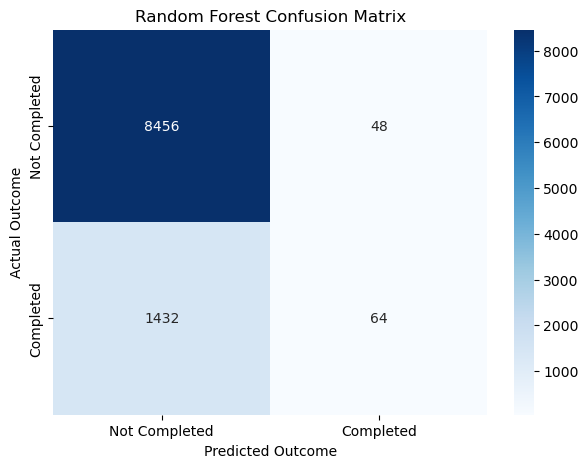

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Completed", "Completed"],
    yticklabels=["Not Completed", "Completed"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [31]:
rf_balanced = Pipeline(steps=[

    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(

        n_estimators=200,

        max_features="sqrt",

        min_samples_leaf=2,

        class_weight="balanced_subsample",

        random_state=42,

        n_jobs=-1

    ))

])

# Train balanced model
rf_balanced.fit(X_train, y_train)

# Generate predictions
y_pred_balanced = rf_balanced.predict(X_test)

y_prob_balanced = rf_balanced.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred_balanced
))

print(
    "Balanced ROC-AUC:",
    roc_auc_score(y_test, y_prob_balanced)
)

              precision    recall  f1-score   support

           0       0.91      0.85      0.88      8504
           1       0.38      0.53      0.44      1496

    accuracy                           0.80     10000
   macro avg       0.65      0.69      0.66     10000
weighted avg       0.83      0.80      0.81     10000

Balanced ROC-AUC: 0.7932397572579873


In [32]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(

    rf_model,

    X_train,

    y_train,

    cv=cv,

    scoring=scoring,

    n_jobs=1

)

for metric in scoring:

    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.8515 +/- 0.0011
precision: 0.5516 +/- 0.0495
recall: 0.0398 +/- 0.0051
f1: 0.0742 +/- 0.0093
roc_auc: 0.7773 +/- 0.0044


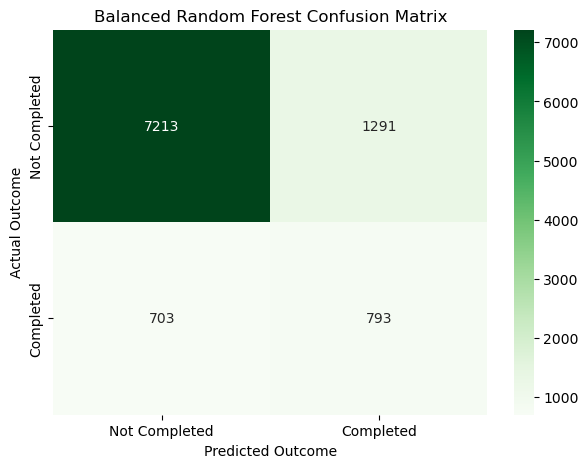

In [33]:
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Completed", "Completed"],
    yticklabels=["Not Completed", "Completed"]
)

plt.title("Balanced Random Forest Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.show()

In [34]:
balanced_cv_results = cross_validate(
    rf_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

for metric in scoring:

    scores = balanced_cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

accuracy: 0.8020 +/- 0.0058
precision: 0.3697 +/- 0.0131
recall: 0.4584 +/- 0.0150
f1: 0.4092 +/- 0.0124
roc_auc: 0.7794 +/- 0.0048


In [35]:
from sklearn.inspection import permutation_importance

# Calculate feature importance on unseen test data
perm_importance = permutation_importance(
    rf_balanced,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

print("Feature importance calculated!")

Feature importance calculated!


In [36]:
feature_importance = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance": perm_importance.importances_mean,

    "Standard_Deviation": perm_importance.importances_std

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                  Feature  Importance  Standard_Deviation
8          booking_origin    0.180155            0.004390
7                   route    0.027812            0.000961
4          length_of_stay    0.019198            0.001062
1           sales_channel    0.012927            0.002052
12        flight_duration    0.011042            0.001365
9     wants_extra_baggage    0.011036            0.001720
3           purchase_lead    0.007802            0.001527
10   wants_preferred_seat    0.006418            0.000684
0          num_passengers    0.002462            0.001158
6              flight_day    0.002359            0.001032
5             flight_hour    0.002053            0.000591
11  wants_in_flight_meals    0.001992            0.000287
2               trip_type    0.000338            0.000455


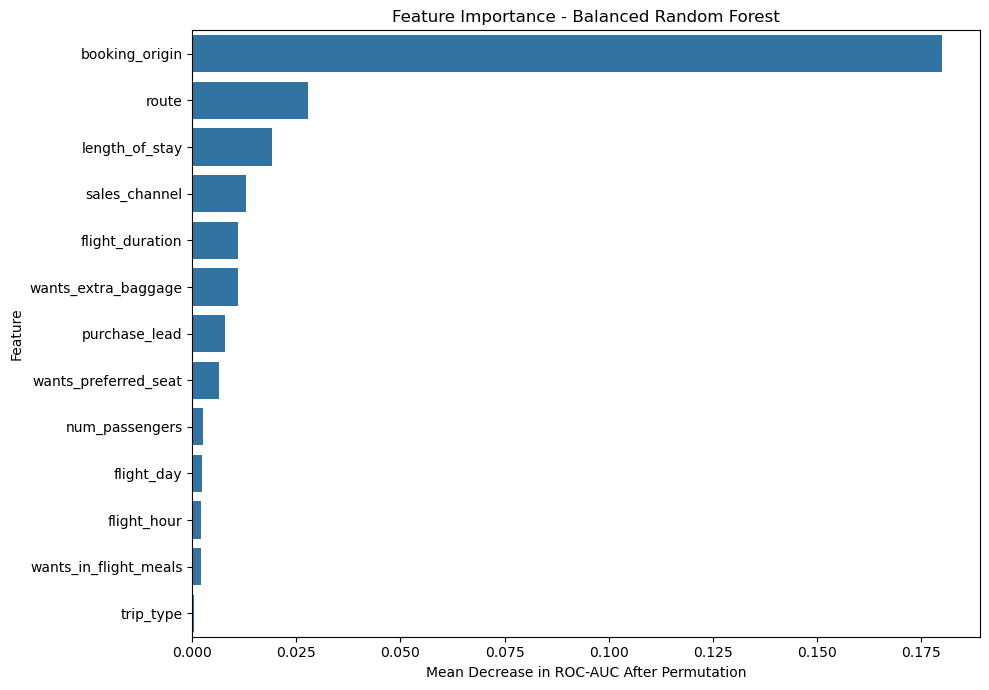

In [37]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Balanced Random Forest")
plt.xlabel("Mean Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [38]:
perm_importance_final = permutation_importance(
    rf_balanced,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

final_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance_final.importances_mean,
    "Std": perm_importance_final.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

print(final_importance)

                  Feature  Importance       Std
8          booking_origin    0.181792  0.006191
7                   route    0.027396  0.001882
4          length_of_stay    0.019325  0.001089
1           sales_channel    0.013074  0.001782
12        flight_duration    0.011162  0.001317
9     wants_extra_baggage    0.010914  0.001421
3           purchase_lead    0.007854  0.001454
10   wants_preferred_seat    0.006357  0.000993
6              flight_day    0.002582  0.001179
11  wants_in_flight_meals    0.002492  0.000772
5             flight_hour    0.002151  0.000672
0          num_passengers    0.001870  0.000861
2               trip_type    0.000344  0.000334


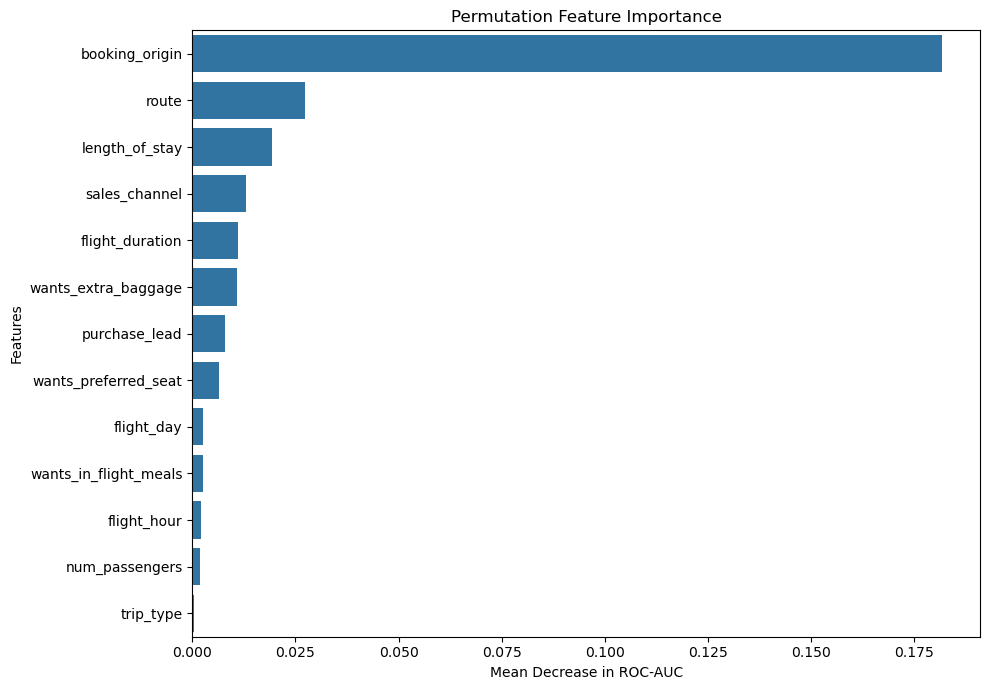

In [39]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=final_importance,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Features")

plt.tight_layout()
plt.savefig(
    "BA_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()